<h1><center> Jour 17 – Outliers, Data Types, Parsing Dates

In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


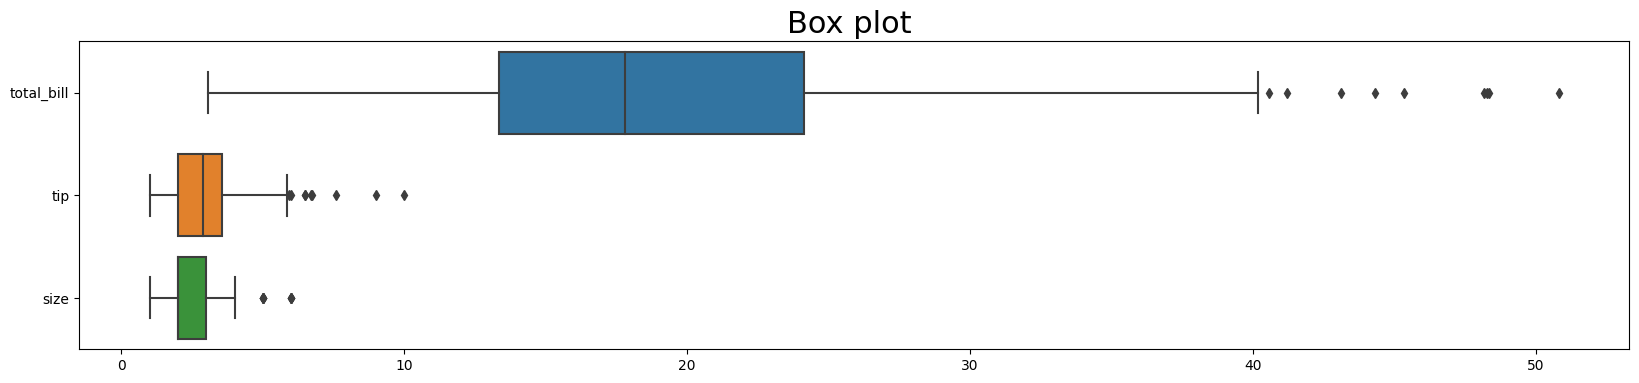

In [14]:
plt.figure(figsize=(20,4))
plt.title("Box plot ", fontsize=22)
sns.boxplot(data= tips, orient="h",)
plt.show()

In [21]:
# Zscore
data = pd.DataFrame({
    "age": [10, 12, 13, 15, 100]
})

print("la moyenne: ", data.mean())
print("l'ecart type: ", data.std())

la moyenne:  age    30.0
dtype: float64
l'ecart type:  age    39.172695
dtype: float64


In [27]:
print((100-30)/39.172695)  # zscore manuelle


from scipy.stats import zscore
data["age_score"] = zscore(data["age"])
print(data)

1.7869590029483549
   age  age_score
0   10  -0.570823
1   12  -0.513741
2   13  -0.485200
3   15  -0.428117
4  100   1.997881


In [ ]:
# IQR
Q1= data["age"].quantile(0.25)
Q3= data["age"].quantile(0.75)
IQR = iqr(data["age"])

from scipy.stats import iqr
print("haaa", iqr(data["age"]))

borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

print("Q1:", Q1, " Q3:", Q3, " IQR:", IQR)
print("Borne inf:", borne_inf, " Borne sup:", borne_sup)

# Détection outliers
data["outlier_IQR"] = (data["age"] < borne_inf) | (data["age"] > borne_sup)
print(data)

haaa 3.0
Q1: 12.0  Q3: 15.0  IQR: 3.0
Borne inf: 7.5  Borne sup: 19.5
   age  age_score  outlier_IQR
0   10  -0.570823        False
1   12  -0.513741        False
2   13  -0.485200        False
3   15  -0.428117        False
4  100   1.997881         True


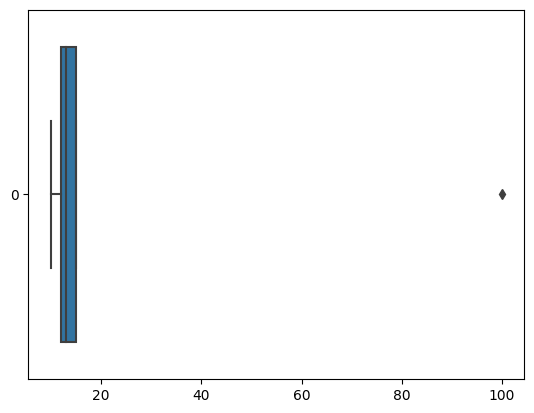

In [ ]:
sns.boxplot(data["age"], orient='h')  # 1 outlier 
plt.show()

In [40]:
import pandas as pd
import numpy as np

data = pd.DataFrame({"age": [10, 12, 13, 15, 100]})

Q1 = data["age"].quantile(0.25)
Q3 = data["age"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR


In [37]:
# supprimer outlier

data_clean = data[(data["age"] >= lower) & (data["age"] <= upper)]
print(data_clean)


   age
0   10
1   12
2   13
3   15


In [39]:
# remplacer par mean ou median
median_age = data["age"].median()
data_median = data.copy()
data_median["age"] = data_median["age"].clip(lower=lower, upper=upper)  # clip remplace directement
print(data_median)


    age
0  10.0
1  12.0
2  13.0
3  15.0
4  19.5


In [41]:
# transformation log
data_log = data.copy()
data_log["age_log"] = np.log(data_log["age"])  # fonctionne sur toutes les valeurs >0
print(data_log)


   age   age_log
0   10  2.302585
1   12  2.484907
2   13  2.564949
3   15  2.708050
4  100  4.605170
